<a href="https://colab.research.google.com/github/P-shettar/ML-LAB-02/blob/main/Experiment_6_%E2%80%93_Bagging_and_Boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (569, 30)
Target Classes: ['malignant' 'benign']
Training Data: (455, 30)
Testing Data: (114, 30)

 BAGGING - RANDOM FOREST
----------------------------------------
Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1 Score: 0.9655172413793104

Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


 BOOSTING - ADABOOST
----------------------------------------
Accuracy: 0.956140350877193
Precision: 0.9466666666666667
Recall: 0.9861111111111112
F1 Score: 0.9659863945578231

Confusion Matrix:
[[38  4]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.97 

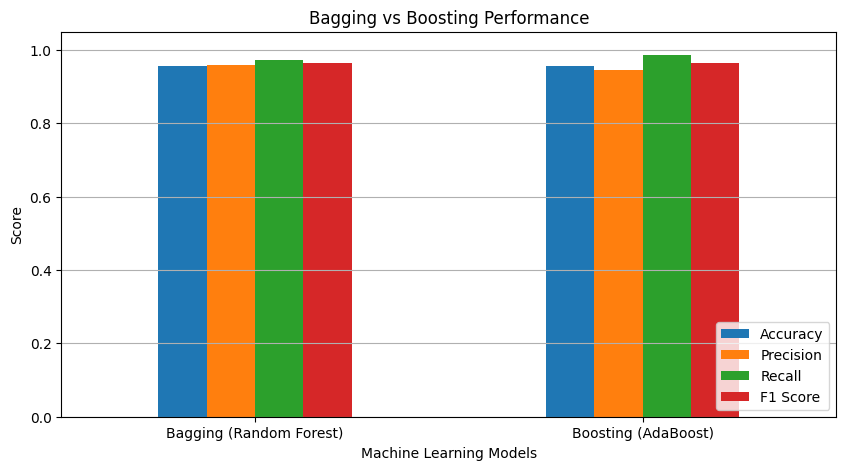

In [1]:

# EXPERIMENT 6: BAGGING AND BOOSTING

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Step 2: Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)
print("Target Classes:", data.target_names)

# Step 3: Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Step 4: Create Bagging model (Random Forest)
bagging_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

bagging_model.fit(X_train, y_train)

# Step 5: Create Boosting model (AdaBoost)
boosting_model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

boosting_model.fit(X_train, y_train)

# Step 6: Make predictions
bagging_pred = bagging_model.predict(X_test)
boosting_pred = boosting_model.predict(X_test)

# Step 7: Evaluate models
def evaluate_model(name, y_true, y_pred):
    print("\n", name)
    print("-" * 40)

    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred, target_names=data.target_names
    ))

evaluate_model("BAGGING - RANDOM FOREST", y_test, bagging_pred)
evaluate_model("BOOSTING - ADABOOST", y_test, boosting_pred)

# Step 8: Compare model performance
results = pd.DataFrame({
    "Model": ["Bagging (Random Forest)", "Boosting (AdaBoost)"],
    "Accuracy": [
        accuracy_score(y_test, bagging_pred),
        accuracy_score(y_test, boosting_pred)
    ],
    "Precision": [
        precision_score(y_test, bagging_pred),
        precision_score(y_test, boosting_pred)
    ],
    "Recall": [
        recall_score(y_test, bagging_pred),
        recall_score(y_test, boosting_pred)
    ],
    "F1 Score": [
        f1_score(y_test, bagging_pred),
        f1_score(y_test, boosting_pred)
    ]
})

print("\nMODEL COMPARISON")
print(results)

# Step 9: Plot comparison graph
results.set_index("Model").plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1.05)
)

plt.title("Bagging vs Boosting Performance")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()
